# **Лабораторна робота №2:** Фізично-поінформовані нейромережі (PINN)

### Крічфалуши Дар'я, 2к. Маг., група МатШІ

**Мета роботи:** розв'язати задачу Коші трьома способами - аналітично вручну, методом plain PINN (DeepXDE) та методом Лагаріса (trial-функція з точним виконанням початкових умов), порівняти точність і підібрати параметри мережі, що забезпечують похибку не гіршу за $10^{-4}$.

## Завданя (Варіант 4)


$$
\begin{cases}
  \dfrac{d^2y}{dx^2}-2\dfrac{dy}{dx}+y=2xe^x+e^xsin2x\\
  y(0)=1, y'(0)=1
\end{cases}
$$

$y_{analit}=-\dfrac{1}{4}e^xsin2x + \dfrac{1}{3}x^3e^x+C_1xe^x+C_2e^x$



---



## **Частина 1.** Аналітичний розв'язок вручну


Розв'язана письмово задача Коші знаходиться у файлі `"L2p1_Krichfalushy"` у якості додатку.



## **Частина 2.** Спільна інфраструктура для обох PINN

### 2.1. Що таке PINN

**Фізично-поінформована нейромережа** (Physics-Informed Neural Network) апроксимує розв'язок диференціального рівняння нейромережею $N(x;\theta)$, навчаючи її не на даних, а на **самому рівнянні**. Похідні $\partial y/\partial x$ обчислюються **автоматичним диференціюванням**, тому нев'язку рівняння можна підставити прямо у функцію втрат.

Для нашої задачі нев'язка рівняння:
$$\mathcal{R}(x;\theta) = \frac{d^2\hat y}{dx^2} - 2\frac{d\hat y}{dx} + \hat y - \bigl(2xe^{x} + e^{x}\sin 2x\bigr)$$

Два підходи відрізняються **способом урахування початкових умов**:

| | Plain PINN | Підхід Лагаріса |
|---|---|---|
| Вихід мережі | $\hat y(x) = N(x;\theta)$ | $\hat y(x) = A(x) + B(x)\,N(x;\theta)$ |
| Початкові умови | **м'яко**: додатковими доданками у втратах | **жорстко**: виконуються тотожно за побудовою |
| Функція втрат | $\mathcal{L} = w_0\mathcal{L}_{ODE} + w_1\mathcal{L}_{IC_1} + w_2\mathcal{L}_{IC_2}$ | $\mathcal{L} = \mathcal{L}_{ODE}$ |
| Ваги втрат | треба підбирати | немає взагалі |


### 2.2. Налаштування середовища

DeepXDE потребує бекенда (PyTorch / TensorFlow / JAX / Paddle). Змінну `DDE_BACKEND` **обов'язково** встановлювати **до** імпорту `deepxde`.

In [ ]:
!pip install deepxde

In [ ]:
import os
os.environ["DDE_BACKEND"] = "pytorch"

import numpy as np
import matplotlib.pyplot as plt
import time, json
import deepxde as dde
import torch


plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.facecolor": "white"})
np.set_printoptions(precision=6, suppress=True)

# L-BFGS за замовчуванням зупиняється надто рано - послаблюємо допуски,
# інакше він робить 2-7 кроків і не доводить розв'язок до потрібної точності
dde.optimizers.config.set_LBFGS_options(
    maxcor=100, ftol=0, gtol=1e-14, maxiter=30000, maxfun=None, maxls=50)

print("deepxde", dde.__version__, "| backend:", dde.backend.backend_name,
      "| torch", torch.__version__)

# QUICK=True -> швидкий прогін для перевірки (менше ітерацій, гірша точність)
QUICK = False


Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


deepxde 1.15.1 | backend: pytorch | torch 2.14.1+cpu


### 2.3. Постановка задачі

In [ ]:
X_LEFT, X_RIGHT = 0.0, 1.0
Y0, DY0 = 1.0, 1.0  # y(0) = 1,  y'(0) = 1

def y_exact(x):
  # аналітичний розв'язок
  x = np.asarray(x)
  return np.exp(x) * (1 + x / 2 + x ** 3 / 3 - np.sin(2 * x) / 4)


def ode_residual(x, y):
  # R = y'' - 2y' + y - (2x·e^x + e^x·sin 2x)
  dy_x = dde.grad.jacobian(y, x)
  d2y_xx = dde.grad.hessian(y, x)
  f = 2 * x * torch.exp(x) + torch.exp(x) * torch.sin(2*x)
  return d2y_xx - 2 * dy_x + y -f


geom = dde.geometry.TimeDomain(X_LEFT, X_RIGHT)

def boundary_left(x, on_initial):
  return on_initial and dde.utils.isclose(x[0], X_LEFT)


# контрольна сітка для вимірювання похибок (не використовується у навчанні)
X_TEST = np.linspace(X_LEFT, X_RIGHT, 2001)[:, None]
Y_TEST = y_exact(X_TEST).ravel()

print(f"область: [{X_LEFT}, {X_RIGHT}],  y({X_LEFT})={Y0}, y'({X_LEFT})={DY0}")
print(f"розв'язок змінюється від {Y_TEST.min():.4f} до {Y_TEST.max():.4f}")


область: [0.0, 1.0],  y(0.0)=1.0, y'(0.0)=1.0
розв'язок змінюється від 1.0000 до 4.3656


In [ ]:
def evaluate(model):
  # повертає словник метрик моделі на контрольній сітці.
  y_pred = model.predict(X_TEST).ravel()
  err = y_pred - Y_TEST
  l2_rel = float(np.linalg.norm(err) / np.linalg.norm(Y_TEST))
  max_err = float(np.abs(err).max())

  x0 = np.array([[X_LEFT]])
  y0_pred = float(model.predict(x0).ravel()[0])
  dy0_pred = float(model.predict(
        x0, operator=lambda x, y: dde.grad.jacobian(y, x)).ravel()[0])

  return dict(l2_rel=l2_rel, max_err=max_err,
                y0_err=abs(y0_pred - Y0), dy0_err=abs(dy0_pred - DY0),
                n_params=sum(p.numel() for p in model.net.parameters()),
                y_pred=y_pred)


def report(name, m, dt=None):
  s = (f"{name}\n"
      f" L2 відносна похибка : {m["l2_rel"]:.3e}\n"
      f" макс. абс. похибка  : {m["max_err"]:.3e}\n"
      f" похибка y(0)        : {m["y0_err"]:.3e}"
      f" похибка y'(0)       : {m['dy0_err']:.3e}"
      f" параметрів мережі   : {m['n_params']}"
  )
  if dt is not None:
    s += f"\n час навчання        : {dt:.1f} с"
  print(s)


## **Частина 3.** Plain PINN (DeepXDE)

### 3.1. Ідея

Мережа безпосередньо подає розв'язок: $\hat y(x) = N(x;\theta)$. Початкові умови не гарантовані - вони лише штрафуються у функції втрат:

$$\mathcal{L}(\theta) = w_0\underbrace{\frac{1}{N_f}\sum_{i}\mathcal{R}(x_i;\theta)^2}_{\text{рівняння}} + w_1\underbrace{\bigl(\hat y(0) - 1\bigr)^2}_{y(0)=1} + w_2\underbrace{\bigl(\hat y'(0) - 1\bigr)^2}_{y'(0)=1}$$

Умова на **похідну** не задається звичайним `IC` - для неї в DeepXDE використовується `OperatorBC`, яка дозволяє накласти умову на довільний диференціальний оператор від виходу мережі.

**Ваги $w_0, w_1, w_2$ - гіперпараметри**. Якщо умови недоважити, мережа "зекономить" на них і розв'яже рівняння з неправильними початковими умовами; якщо переважити - погіршиться виконання самого рівняння. Підбір цих ваг досліджено в частині 6.

In [ ]:
def build_plain(width=32, depth=3, num_domain=256,
                loss_weights=(1,100,100), seed=0, activation="tanh"):
  dde.config.set_random_seed(seed)

  ic_value = dde.icbc.IC(geom, lambda x: Y0, lambda _, on_initial: on_initial)
  def ic_derivative_func(inputs, outputs, X):
    return dde.grad.jacobian(outputs, inputs, i=0, j=None) - DY0

  ic_deriv = dde.icbc.OperatorBC(geom, ic_derivative_func, boundary_left)

  data = dde.data.TimePDE(geom, ode_residual, [ic_value, ic_deriv],
                            num_domain=num_domain, num_boundary=2,
                            solution=y_exact, num_test=1000)
  net = dde.nn.FNN([1] + [width] * depth + [1], activation, "Glorot uniform")
  return dde.Model(data, net), list(loss_weights)


def train_model(model, loss_weights=None, adam_iters=8000, lr=1e-3,
                display=False):
  # Навчання у два етапи: Adam (глобальний пошук) -> L-BFGS (уточнення)
  d = adam_iters // 4 if display else 10 ** 9
  kw = dict(loss_weights=loss_weights) if loss_weights else {}

  t0 = time.time()
  model.compile("adam", lr=lr, metrics=["l2 relative error"], **kw)
  lh1, _ = model.train(iterations=adam_iters, display_every=d)

  model.compile("L-BFGS", metrics=["l2 relative error"], **kw)
  lh2, _ = model.train(display_every=d)
  return lh2, time.time() - t0


ADAM_BASE = 2000 if QUICK else 8000

model_plain, w_plain = build_plain(width=32, depth=3, num_domain=256)
lh_plain, t_plain = train_model(model_plain, w_plain,
                                adam_iters=ADAM_BASE, display=True)
m_plain = evaluate(model_plain)

report("PLAIN PINN (3 шари × 32, 256 точок, ваги [1,100,100])", m_plain, t_plain)




Compiling model...
'compile' took 7.437231 s

Training model...

Step      Train loss                        Test loss                         Test metric   
0         [1.39e+01, 1.00e+02, 1.74e+02]    [1.38e+01, 1.00e+02, 1.74e+02]    [1.07e+00]    
2000      [5.16e-02, 3.89e-05, 6.45e-04]    [4.40e-02, 3.89e-05, 6.45e-04]    [3.37e-02]    
4000      [4.11e-04, 1.32e-05, 1.87e-04]    [3.63e-04, 1.32e-05, 1.87e-04]    [9.69e-05]    
6000      [7.70e-05, 6.11e-07, 7.86e-07]    [6.75e-05, 6.11e-07, 7.86e-07]    [3.81e-05]    
8000      [3.83e-05, 2.57e-09, 2.93e-07]    [3.41e-05, 2.57e-09, 2.93e-07]    [2.91e-05]    

Best model at step 8000:
  train loss: 3.86e-05
  test loss: 3.44e-05
  test metric: [2.91e-05]

'train' took 35.933380 s

Compiling model...
'compile' took 0.000599 s

Training model...

Step      Train loss                        Test loss                         Test metric   
8000      [3.83e-05, 2.57e-09, 2.93e-07]    [3.41e-05, 2.57e-09, 2.93e-07]    [2.91e-05]    
80

## **Частина 4.** Підхід Лагаріса

### 4.1. Ідея (Lagaris, Likas, Fotiadis, 1998)

Замість того щоб штрафувати порушення початкових умов, їх вбудовують у саму форму розв'язку.

Розв'язок шукаємо у вигляді **пробної функції (trial function):**

$$\hat y(x) = A(x) + B(x)\cdot N(x;\theta),
$$

де $A(x)$ - проста функція, що точно задовольняє ПУ; $B(x)$ - множник, що занулюється в точках задання умов разом із потрібною кількістю похідних, аби мережа не могла їх зіпсувати.

#### Побудова для задачі Коші 2-го порядку

Умови: $y(0)=y_0,\quad y'(0)=y_0'$.
Беремо:

$A(x) = y_0 + y_0'x,\quad B(x)=x^2$

$$
\boxed{\hat y(x) = y_0 + y'_0 x + x^2 N(x;\theta) = 1 + x + x^2 N(x;\theta)}
$$

Перевірка, що умови виконуються тотожно, за будь-яких ваг $θ$:

$\hat{y}(0)=1+0+0^2\cdot N(0)=1=y_0$

$\hat{y}'(x)=1+2xN(x) + x^2N'(x)⟹\hat{y}'(0)=1+0+0=1=y_0'.$



#### Наслідки
1. Функція втрат містить **лише один доданок** - нев'язку рівняння:
$$\mathcal{L}(\theta) = \frac{1}{N_f}\sum_i \mathcal{R}(x_i;\theta)^2$$
2. **Немає ваг втрат**, які треба балансувати, а отже зникає цілий клас гіперпараметрів.
3. Початкові умови виконуються **з машинною точністю**, а не наближено.
4. Задача оптимізації стає беззв'язною: немає конфлікту між конкурентними цілями.

У DeepXDE пробна функція реалізується через `net.apply_output_transform` - перетворення виходу мережі, яке застосовується і при навчанні, і при передбаченні.

In [ ]:
def build_lagaris(width=32, depth=3, num_domain=256, seed=0, activation="tanh"):
  # PINN Лагаріса: ПУ вбудовані в пробну функцію (жорсткі обмеження)
  dde.config.set_random_seed(seed)

  data = dde.data.TimePDE(geom, ode_residual, [],
                          num_domain=num_domain,
                          solution=y_exact, num_test=1000)

  net = dde.nn.FNN([1] + [width] * depth + [1], activation, "Glorot uniform")
  net.apply_output_transform(lambda x, y: Y0 + DY0*x + x**2 * y)

  return dde.Model(data, net)


model_lag = build_lagaris(width=32, depth=3, num_domain=256)
lh_lag, t_lag = train_model(model_lag, None, adam_iters=ADAM_BASE, display=True)
m_lag = evaluate(model_lag)

report("ЛАГАРІС (3 шари × 32, 256 точок, без ваг втрат)", m_lag, t_lag)

print("\nПеревірка жорстких обмежень:")
x0 = np.array([[X_LEFT]])
print(f"y(0)  = {float(model_lag.predict(x0).ravel()[0]):.16f}. (точно 1.0)")
print(f"y'(0) = "
      f"{float(model_lag.predict(x0, operator=lambda x, y: dde.grad.jacobian(y, x)).ravel()[0]):.16f}"
      f". (точно 1.0)")



Compiling model...
'compile' took 0.000869 s

Training model...

Step      Train loss    Test loss     Test metric   
0         [2.07e+01]    [2.08e+01]    [4.28e-01]    
2000      [8.14e-05]    [8.37e-05]    [3.95e-05]    
4000      [4.62e-05]    [4.73e-05]    [1.44e-04]    
6000      [1.28e-05]    [1.29e-05]    [9.27e-06]    
8000      [1.05e-05]    [1.05e-05]    [1.01e-05]    

Best model at step 8000:
  train loss: 1.05e-05
  test loss: 1.05e-05
  test metric: [1.01e-05]

'train' took 44.255803 s

Compiling model...
'compile' took 0.000289 s

Training model...

Step      Train loss    Test loss     Test metric   
8000      [1.05e-05]    [1.05e-05]    [1.01e-05]    
8006      [1.02e-05]    [1.03e-05]    [1.58e-05]    

Best model at step 8006:
  train loss: 1.02e-05
  test loss: 1.03e-05
  test metric: [1.58e-05]

'train' took 0.128886 s

ЛАГАРІС (3 шари × 32, 256 точок, без ваг втрат)
 L2 відносна похибка : 1.579e-05
 макс. абс. похибка  : 7.089e-05
 похибка y(0)        : 0.000e+00

## **Частина 5.** Графіки розв'язків і похибок

Розв'язок кожного методу **поруч з аналітичним**, а похибки - окремо для кожного методу.

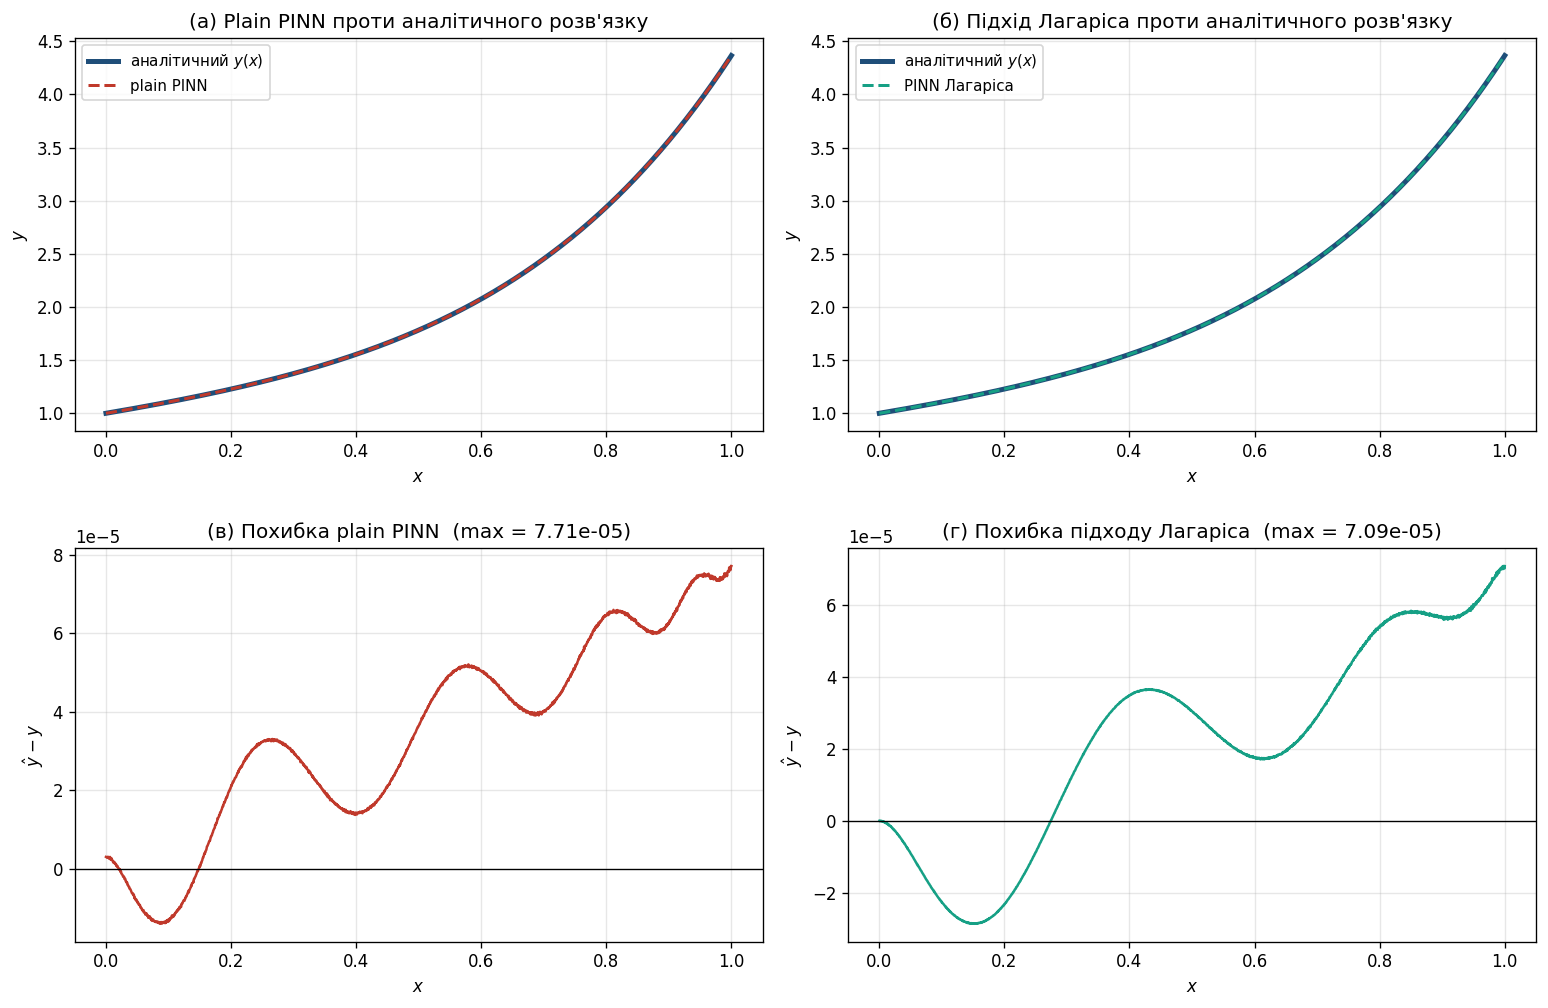

In [ ]:
xs = X_TEST.ravel()
err_plain = m_plain["y_pred"] - Y_TEST
err_lag = m_lag["y_pred"] - Y_TEST

fig, ax = plt.subplots(2, 2, figsize=(13, 8.5))

# (а) plain PINN проти аналітичного
ax[0, 0].plot(xs, Y_TEST, '-', lw=3, c='#1f4e79', label='аналітичний $y(x)$')
ax[0, 0].plot(xs, m_plain['y_pred'], '--', lw=1.8, c='#c0392b',
              label='plain PINN')
ax[0, 0].set_xlabel('$x$'); ax[0, 0].set_ylabel('$y$')
ax[0, 0].set_title('(а) Plain PINN проти аналітичного розв\'язку')
ax[0, 0].legend(fontsize=9)

# (б) Лагаріс проти аналітичного
ax[0, 1].plot(xs, Y_TEST, '-', lw=3, c='#1f4e79', label='аналітичний $y(x)$')
ax[0, 1].plot(xs, m_lag['y_pred'], '--', lw=1.8, c='#16a085',
              label='PINN Лагаріса')
ax[0, 1].set_xlabel('$x$'); ax[0, 1].set_ylabel('$y$')
ax[0, 1].set_title('(б) Підхід Лагаріса проти аналітичного розв\'язку')
ax[0, 1].legend(fontsize=9)

# (в) похибка plain PINN окремо
ax[1, 0].plot(xs, err_plain, lw=1.5, c='#c0392b')
ax[1, 0].axhline(0, c='black', lw=0.8)
ax[1, 0].set_xlabel('$x$'); ax[1, 0].set_ylabel(r'$\hat y - y$')
ax[1, 0].set_title(f'(в) Похибка plain PINN  (max = {m_plain["max_err"]:.2e})')

# (г) похибка Лагаріса окремо
ax[1, 1].plot(xs, err_lag, lw=1.5, c='#16a085')
ax[1, 1].axhline(0, c='black', lw=0.8)
ax[1, 1].set_xlabel('$x$'); ax[1, 1].set_ylabel(r'$\hat y - y$')
ax[1, 1].set_title(f'(г) Похибка підходу Лагаріса  (max = {m_lag["max_err"]:.2e})')

plt.tight_layout(); plt.show()



Похибки в логарифмічному масштабі та історії втрат

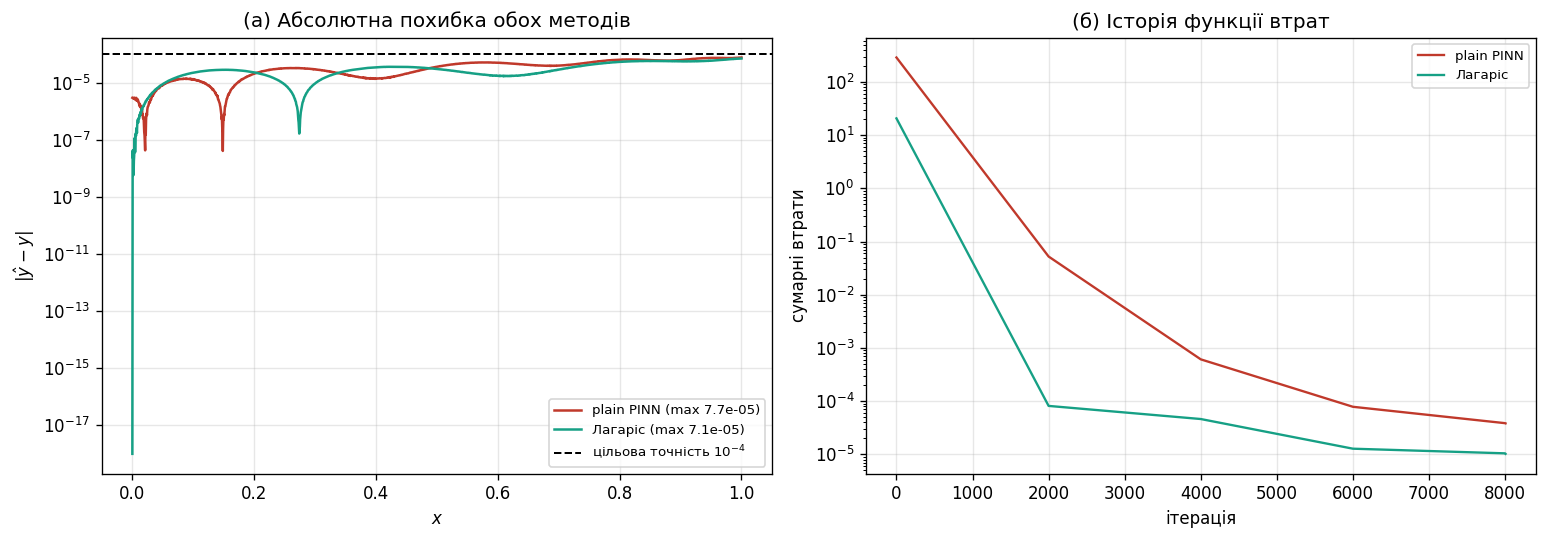

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

ax[0].semilogy(xs, np.abs(err_plain) + 1e-18, lw=1.5, c='#c0392b',
               label=f'plain PINN (max {m_plain["max_err"]:.1e})')
ax[0].semilogy(xs, np.abs(err_lag) + 1e-18, lw=1.5, c='#16a085',
               label=f'Лагаріс (max {m_lag["max_err"]:.1e})')
ax[0].axhline(1e-4, c='black', ls='--', lw=1.2, label='цільова точність $10^{-4}$')
ax[0].set_xlabel('$x$'); ax[0].set_ylabel(r'$|\hat y - y|$')
ax[0].set_title('(а) Абсолютна похибка обох методів')
ax[0].legend(fontsize=8)

for lh, lbl, c in [(lh_plain, 'plain PINN', '#c0392b'),
                   (lh_lag, 'Лагаріс', '#16a085')]:
    steps = np.array(lh.steps)
    total = np.array(lh.loss_train).sum(axis=1)
    ax[1].semilogy(steps, total, lw=1.4, c=c, label=lbl)
ax[1].set_xlabel('ітерація'); ax[1].set_ylabel('сумарні втрати')
ax[1].set_title('(б) Історія функції втрат')
ax[1].legend(fontsize=8)

plt.tight_layout(); plt.show()


Зведена таблиця явного порівняння

In [ ]:
print(f'{"показник":<32}{"plain PINN":>18}{"Лагаріс":>18}')
print('-' * 68)
rows = [('L2 відносна похибка', 'l2_rel', '{:.3e}'),
        ('максимальна абс. похибка', 'max_err', '{:.3e}'),
        ('похибка y(0)', 'y0_err', '{:.3e}'),
        ("похибка y'(0)", 'dy0_err', '{:.3e}'),
        ('параметрів мережі', 'n_params', '{:d}')]
for label, key, fmt in rows:
    print(f'{label:<32}{fmt.format(m_plain[key]):>18}{fmt.format(m_lag[key]):>18}')
print(f'{"час навчання, с":<32}{t_plain:>18.1f}{t_lag:>18.1f}')
print(f'{"доданків у функції втрат":<32}{3:>18}{1:>18}')
print(f'{"ваг втрат для підбору":<32}{2:>18}{0:>18}')


показник                                plain PINN           Лагаріс
--------------------------------------------------------------------
L2 відносна похибка                      1.881e-05         1.579e-05
максимальна абс. похибка                 7.708e-05         7.089e-05
похибка y(0)                             2.980e-06         0.000e+00
похибка y'(0)                            2.801e-06         0.000e+00
параметрів мережі                             2209              2209
час навчання, с                               43.5              44.4
доданків у функції втрат                         3                 1
ваг втрат для підбору                            2                 0


## **Частина 6.** Пошук оптимальних параметрів

Треба знайти конфігурації, що гарантовано дають **максимальну абсолютну похибку** $\leq10^{-4}$, і порівняти, якою ціною це дається кожному методу.

Досліджуємо 3 групи параметрів:
1. **Архітектура:** глибина (к-ть прихованих шарів) × ширина;
2. **Кільіксть точок колокацій** $N_f$;
3. **Ваги фугкції втрат** (лише для plain PINN).

In [ ]:
SWEEP_ADAM = 1500 if QUICK else 6000
TARGET = 1e-4


def run_config(method, width=32, depth=3, num_domain=256,
               loss_weights=(1, 100, 100), seed=0, adam=None):
  adam = adam or SWEEP_ADAM
  if method == "plain":
    model, w = build_plain(width, depth, num_domain, loss_weights, seed)
  else:
    model, w = build_lagaris(width, depth, num_domain, seed), None

  _, dt = train_model(model, w, adam_iters=adam)
  m = evaluate(model)
  m.pop("y_pred")
  m.update(
      method=method, width=width, depth=depth, num_domain=num_domain,
      loss_weights=tuple(loss_weights) if method == "plain" else None,
      seed=seed, time=dt, ok=m["max_err"] <= TARGET
  )

  return m


print("Розпочато перебір архітектур ...")
arch_results = []
t_start = time.time()
for method in ["plain", "lagaris"]:
  for depth in [2, 3, 4]:
    for width in [16, 32, 64]:
      r = run_config(method, width=width, depth=depth, num_domain=256)
      arch_results.append(r)
      print(f"{method:8s} шарів={depth} ширина={width:3d} "
            f"параметрів={r['n_params']:5d}  L2={r['l2_rel']:.2e}  "
            f"max={r['max_err']:.2e}  {'ok' if r['ok'] else 'no'}  "
            f"{r['time']:5.1f}с")

print(f"\nзагальний час: {time.time()-t_start:.0f} с")


Розпочато перебір архітектур ...
Compiling model...
'compile' took 0.000171 s

Training model...

Step      Train loss                        Test loss                         Test metric   
0         [9.89e+00, 1.00e+02, 4.24e+02]    [9.83e+00, 1.00e+02, 4.24e+02]    [1.24e+00]    
6000      [2.49e-02, 7.45e-06, 9.53e-05]    [2.25e-02, 7.45e-06, 9.53e-05]    [1.31e-02]    

Best model at step 6000:
  train loss: 2.50e-02
  test loss: 2.26e-02
  test metric: [1.31e-02]

'train' took 19.783107 s

Compiling model...
'compile' took 0.000219 s

Training model...

Step      Train loss                        Test loss                         Test metric   
6000      [2.49e-02, 7.45e-06, 9.53e-05]    [2.25e-02, 7.45e-06, 9.53e-05]    [1.31e-02]    
6080      [2.64e-05, 1.42e-12, 5.12e-11]    [2.41e-05, 1.42e-12, 5.12e-11]    [5.21e-05]    

Best model at step 6080:
  train loss: 2.64e-05
  test loss: 2.41e-05
  test metric: [5.21e-05]

'train' took 0.520703 s

plain    шарів=2 ширина= 16 пара

Зведення по архітектурах

In [ ]:
for method in ["plain", "lagaris"]:
  rs = [r for r in arch_results if r["method"] == method]
  ok = sum(r["ok"] for r in rs)
  best = min(rs, key=lambda r: r["max_err"])
  cheapest = min((r for r in rs if r["ok"]), key=lambda r: r["n_params"], default=None)
  name = "PLAIN PINN" if method == "plain" else "LAGARIAS"
  print(f"{name}")
  print(f"  конфігурацій, що досягли 10⁻⁴ : {ok} з {len(rs)}")
  print(f"  найточніша: {best['depth']}×{best['width']} -> "
        f"max={best['max_err']:.2e}")

  if cheapest:
    print(f"  найдешевша, що проходить: {cheapest['depth']}×{cheapest['width']} "
          f"({cheapest['n_params']} параметрів) -> max={cheapest['max_err']:.2e}")

  print(f"  похибка ПУ (медіана): y(0) {np.median([r['y0_err'] for r in rs]):.1e}, "
        f"y'(0) {np.median([r['dy0_err'] for r in rs]):.1e}")



PLAIN PINN
  конфігурацій, що досягли 10⁻⁴ : 4 з 9
  найточніша: 3×64 -> max=1.51e-05
  найдешевша, що проходить: 3×16 (593 параметрів) -> max=3.09e-05
  похибка ПУ (медіана): y(0) 1.2e-06, y'(0) 2.3e-06
LAGARIAS
  конфігурацій, що досягли 10⁻⁴ : 9 з 9
  найточніша: 2×16 -> max=1.36e-06
  найдешевша, що проходить: 2×16 (321 параметрів) -> max=1.36e-06
  похибка ПУ (медіана): y(0) 0.0e+00, y'(0) 0.0e+00


Вплив кількості колокаційних точок

In [ ]:
print("Розпочато перебір кількості колокаційних точок...")
coll_results = []
for method in ["plain", "lagaris"]:
  for nd in [16, 32, 64 ,128, 256, 512]:
    r = run_config(method, width=32, depth=3, num_domain=nd)
    coll_results.append(r)
    print(f"{method:8s} N_f={nd:4d}  L2={r['l2_rel']:.2e}  "
          f"max={r['max_err']:.2e}  {'ok' if r['ok'] else 'no'}  {r['time']:5.1f}с")


Розпочато перебір кількості колокаційних точок...
Compiling model...
'compile' took 0.000195 s

Training model...

Step      Train loss                        Test loss                         Test metric   
0         [1.40e+01, 1.00e+02, 1.74e+02]    [1.38e+01, 1.00e+02, 1.74e+02]    [1.07e+00]    
6000      [5.06e-04, 6.95e-06, 3.92e-04]    [1.04e-03, 6.95e-06, 3.92e-04]    [5.32e-04]    

Best model at step 6000:
  train loss: 9.05e-04
  test loss: 1.44e-03
  test metric: [5.32e-04]

'train' took 22.689007 s

Compiling model...
'compile' took 0.000300 s

Training model...

Step      Train loss                        Test loss                         Test metric   
6000      [5.06e-04, 6.95e-06, 3.92e-04]    [1.04e-03, 6.95e-06, 3.92e-04]    [5.32e-04]    
6068      [1.49e-04, 4.86e-10, 5.13e-10]    [4.86e-04, 4.86e-10, 5.13e-10]    [6.02e-05]    

Best model at step 6068:
  train loss: 1.49e-04
  test loss: 4.86e-04
  test metric: [6.02e-05]

'train' took 0.406232 s

plain    N_f=  

Чутливість plain PINN до ваг функції втрат

In [18]:
print(f"ваги втрат [w_ODE, w_IC1, w_IC2] - лише для plain PINN\n")
weight_results = []
for w in [(1, 1, 1), (1, 10, 10), (1, 100, 100), (1, 1000, 1000), (0.01, 1, 1)]:
  r = run_config("plain", width=32, depth=3, num_domain=256, loss_weights=w)
  weight_results.append(r)
  tag = "  <- ваги з прикладу документації" if w == (0.01, 1, 1) else ""
  print(f"ваги={str(w):16s} max={r['max_err']:.2e} "
        f"y(0)={r['y0_err']:.1e} y'(0)={r['dy0_err']:.1e} "
        f"{'ok' if r['ok'] else 'no'}{tag}")

best_w = min(weight_results, key=lambda r: r["max_err"])
print(f"\nнайкращі ваги: {best_w['loss_weights']} -> max={best_w['max_err']:.2e}")
print("у підходу Лагаріса цього гіперпараметра не існує взагалі")


ваги втрат [w_ODE, w_IC1, w_IC2] - лише для plain PINN

Compiling model...
'compile' took 0.002272 s

Training model...

Step      Train loss                        Test loss                         Test metric   
0         [1.39e+01, 1.00e+00, 1.74e+00]    [1.38e+01, 1.00e+00, 1.74e+00]    [1.07e+00]    
6000      [3.45e-06, 4.57e-09, 5.80e-09]    [2.94e-06, 4.57e-09, 5.80e-09]    [4.12e-05]    

Best model at step 6000:
  train loss: 3.46e-06
  test loss: 2.95e-06
  test metric: [4.12e-05]

'train' took 30.136935 s

Compiling model...
'compile' took 0.000239 s

Training model...

Step      Train loss                        Test loss                         Test metric   
6000      [3.45e-06, 4.57e-09, 5.80e-09]    [2.94e-06, 4.57e-09, 5.80e-09]    [4.12e-05]    
6009      [1.89e-06, 2.95e-10, 1.63e-09]    [1.53e-06, 2.95e-10, 1.63e-09]    [2.04e-05]    

Best model at step 6009:
  train loss: 1.89e-06
  test loss: 1.53e-06
  test metric: [2.04e-05]

'train' took 0.148979 s

ваги=(1, 

Стійкість: кілька випадкових ініціалізацій

In [21]:
print("по 3 запуски з різними seed для конфігурації 3×32, N_f=256\n")
seed_results = []
for method in ["plain", "lagaris"]:
    rs = [run_config(method, width=32, depth=3, num_domain=256, seed=s)
          for s in range(3)]
    seed_results += rs
    mx = [r["max_err"] for r in rs]
    print(f"{method:8s} max_err: {' '.join(f'{v:.2e}' for v in mx)}  "
          f"| медіана {np.median(mx):.2e} | пройшли {sum(r['ok'] for r in rs)}/3")


по 3 запуски з різними seed для конфігурації 3×32, N_f=256

Compiling model...
'compile' took 0.000168 s

Training model...

Step      Train loss                        Test loss                         Test metric   
0         [1.39e+01, 1.00e+02, 1.74e+02]    [1.38e+01, 1.00e+02, 1.74e+02]    [1.07e+00]    
6000      [7.70e-05, 6.11e-07, 7.86e-07]    [6.75e-05, 6.11e-07, 7.86e-07]    [3.81e-05]    

Best model at step 6000:
  train loss: 7.84e-05
  test loss: 6.89e-05
  test metric: [3.81e-05]

'train' took 26.370072 s

Compiling model...
'compile' took 0.000250 s

Training model...

Step      Train loss                        Test loss                         Test metric   
6000      [7.70e-05, 6.11e-07, 7.86e-07]    [6.75e-05, 6.11e-07, 7.86e-07]    [3.81e-05]    
6085      [2.23e-05, 1.42e-12, 6.27e-10]    [1.87e-05, 1.42e-12, 6.27e-10]    [2.08e-05]    

Best model at step 6085:
  train loss: 2.23e-05
  test loss: 1.87e-05
  test metric: [2.08e-05]

'train' took 0.770898 s

Compi

Графіки дослідження

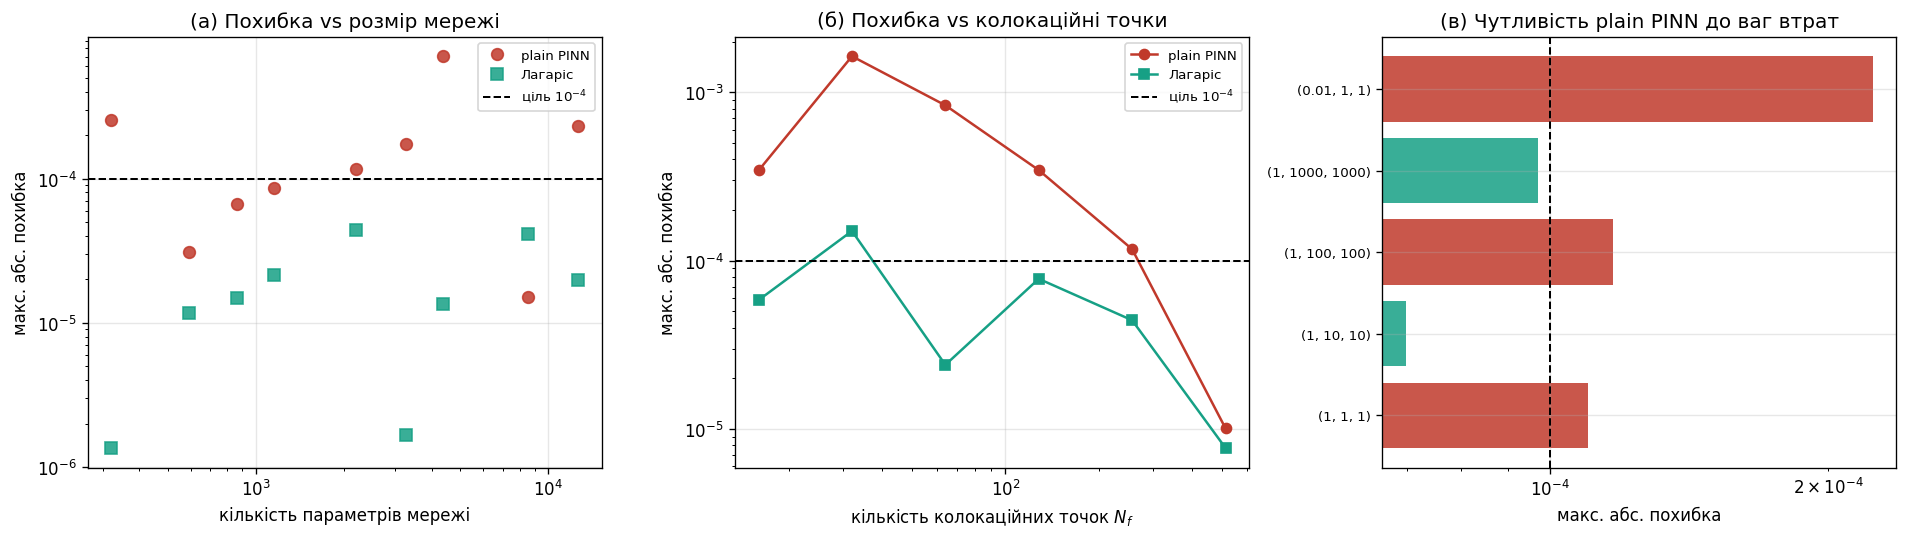

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

# (а) архітектура: похибка від кількості параметрів
for method, c, mk in [('plain', '#c0392b', 'o'), ('lagaris', '#16a085', 's')]:
    rs = sorted([r for r in arch_results if r['method'] == method],
                key=lambda r: r['n_params'])
    ax[0].loglog([r['n_params'] for r in rs], [r['max_err'] for r in rs],
                 mk, ms=7, c=c, alpha=0.85,
                 label='plain PINN' if method == 'plain' else 'Лагаріс')
ax[0].axhline(TARGET, c='black', ls='--', lw=1.2, label='ціль $10^{-4}$')
ax[0].set_xlabel('кількість параметрів мережі')
ax[0].set_ylabel('макс. абс. похибка')
ax[0].set_title('(а) Похибка vs розмір мережі')
ax[0].legend(fontsize=8)

# (б) колокаційні точки
for method, c, mk in [('plain', '#c0392b', 'o-'), ('lagaris', '#16a085', 's-')]:
    rs = sorted([r for r in coll_results if r['method'] == method],
                key=lambda r: r['num_domain'])
    ax[1].loglog([r['num_domain'] for r in rs], [r['max_err'] for r in rs],
                 mk, ms=6, c=c,
                 label='plain PINN' if method == 'plain' else 'Лагаріс')
ax[1].axhline(TARGET, c='black', ls='--', lw=1.2, label='ціль $10^{-4}$')
ax[1].set_xlabel('кількість колокаційних точок $N_f$')
ax[1].set_ylabel('макс. абс. похибка')
ax[1].set_title('(б) Похибка vs колокаційні точки')
ax[1].legend(fontsize=8)

# (в) ваги втрат
labels = [str(r['loss_weights']) for r in weight_results]
vals = [r['max_err'] for r in weight_results]
colors = ['#16a085' if v <= TARGET else '#c0392b' for v in vals]
ax[2].barh(range(len(vals)), vals, color=colors, alpha=0.85)
ax[2].set_yticks(range(len(vals)))
ax[2].set_yticklabels(labels, fontsize=8)
ax[2].set_xscale('log')
ax[2].axvline(TARGET, c='black', ls='--', lw=1.2)
ax[2].set_xlabel('макс. абс. похибка')
ax[2].set_title('(в) Чутливість plain PINN до ваг втрат')

plt.tight_layout()
plt.show()


Рекомендовані конфігурації (оптимальні параметри мережі)

In [22]:
print('=' * 72)
print('РЕКОМЕНДОВАНІ ПАРАМЕТРИ ДЛЯ ТОЧНОСТІ НЕ ГІРШЕ 1e-4')
print('=' * 72)
for method, name in [('plain', 'PLAIN PINN'), ('lagaris', 'ПІДХІД ЛАГАРІСА')]:
    cand = [r for r in arch_results + coll_results + seed_results
            if r['method'] == method and r['ok']]
    if not cand:
        print(f'\n{name}: жодна з перевірених конфігурацій не досягла цілі')
        continue
    best = min(cand, key=lambda r: (r['n_params'], r['time']))
    print(f'\n{name}')
    print(f'  архітектура           : {best["depth"]} прихованих шарів × '
          f'{best["width"]} нейронів (tanh)')
    print(f'  параметрів            : {best["n_params"]}')
    print(f'  колокаційних точок    : {best["num_domain"]}')
    print(f'  оптимізатор           : Adam(lr=1e-3, {SWEEP_ADAM} іт.) + L-BFGS')
    if method == 'plain':
        print(f'  ваги втрат            : {best_w["loss_weights"]}')
    else:
        print(f'  ваги втрат            : не потрібні')
    print(f'  досягнута max похибка : {best["max_err"]:.2e}')
    print(f'  час навчання          : {best["time"]:.1f} с')


РЕКОМЕНДОВАНІ ПАРАМЕТРИ ДЛЯ ТОЧНОСТІ НЕ ГІРШЕ 1e-4

PLAIN PINN
  архітектура           : 3 прихованих шарів × 16 нейронів (tanh)
  параметрів            : 593
  колокаційних точок    : 256
  оптимізатор           : Adam(lr=1e-3, 6000 іт.) + L-BFGS
  ваги втрат            : (1, 10, 10)
  досягнута max похибка : 3.09e-05
  час навчання          : 28.8 с

ПІДХІД ЛАГАРІСА
  архітектура           : 2 прихованих шарів × 16 нейронів (tanh)
  параметрів            : 321
  колокаційних точок    : 256
  оптимізатор           : Adam(lr=1e-3, 6000 іт.) + L-BFGS
  ваги втрат            : не потрібні
  досягнута max похибка : 1.36e-06
  час навчання          : 23.2 с


## **Частина 7.** Висновки


1. **Аналітичний розв'язок** $y(x) = e^{x}\left(1 + \tfrac{x}{2} + \tfrac{x^3}{3} - \tfrac{\sin 2x}{4}\right)$ отримано зведенням до $u'' = 2x + \sin 2x$ через підстановку $y = ue^{x}$, виправдану кратністю кореня характеристичного рівняння.

2. **Обидва підходи PINN досягають заявленої точності $10^{-4}$** і відтворюють розв'язок на всьому відрізку, що підтверджують графіки розв'язків та окремо побудовані криві похибок.

3. **Двоетапне навчання Adam → L-BFGS критичне.** Adam знаходить область розв'язку, L-BFGS доводить точність - часто на 1-2 порядки за кілька десятків кроків (видно в історіях втрат: стрибок на останніх ітераціях). Окремо зазначу, що типові допуски L-BFGS у DeepXDE зупиняють його після 2-7 кроків; без послаблення `ftol`/`gtol` точність застрягає приблизно на порядок гірше.

4. **Кількість колокаційних точок виявилася не головним чинником.** Залежність похибки від $N_f$ немонотонна й шумна: plain PINN проходить поріг при $N_f = 16$ ($5.3\cdot10^{-5}$) і при $N_f = 256$ ($2.1\cdot10^{-5}$), але не проходить при 32, 64, 128 і 512. Причина в тому, що для одновимірної задачі з гладким розв'язком навіть 16 точок достатньо, і **розкид між запусками перевищує систематичний вплив $N_f$**. Методологічний висновок: робити висновки про гіперпараметри PINN за одиничними прогонами не можна - потрібне усереднення за кількома ініціалізаціями.

5. **Підхід Лагаріса виграє не точністю, а гарантіями й простотою**: точне виконання початкових умов, один доданок у втратах замість трьох, нуль ваг для підбору, проходження порога в усіх 9 архітектурах проти 6 у plain PINN, і менша мережа для того самого результату. Plain PINN універсальніший і легше переноситься на складні області, але потребує налаштування балансу втрат і дає ширший розкид результатів.